<a href="https://colab.research.google.com/github/ankitjangir10054-prog/Student-Placement-Classifer/blob/main/Student_Placement_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# pipeline
1. Data Loading

  * Load 1M rows using Pandas or Polars


2. Data Understanding & Cleaning

  * Missing values · Duplicates · Data types · Outliers


3. Exploratory Data Analysis

  * Placement distribution · Correlation · Feature analysis


4. Feature Engineering & Preprocessing

  * Encoding · Scaling · Feature selection


5. Train / Validation / Test Split

  * 70% Training · 15% Validation · 15% Testing

6. Neural Network Architecture (ANN)

  * Input → Hidden Layers → ReLU → Output (Sigmoid)


7. Model Training

  *  BCEWithLogitsLoss · Adam · Backpropagation


8. Model Evaluation

  *  Accuracy · Precision · Recall · F1 · ROC-AUC


9. Deployment

  *  Save model → FastAPI → Prediction interface

In [33]:
import kagglehub

# Download latest version
data = kagglehub.dataset_download("sharmajicoder/student-placement-prediction")

print("Path to dataset files:", data)

Using Colab cache for faster access to the 'student-placement-prediction' dataset.
Path to dataset files: /kaggle/input/student-placement-prediction


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

In [35]:
import os
# List the files in the downloaded directory
files = os.listdir(data)
print("Files in dataset directory:", files)

Files in dataset directory: ['student_placement_dataset_1M.csv']


In [36]:
# Ensure we have the correct path string
# Since 'data' was overwritten with a list, we re-establish the path from kagglehub
dataset_path = kagglehub.dataset_download("sharmajicoder/student-placement-prediction")

# Find CSV files in the directory
csv_files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]

if csv_files:
    # Use the first CSV file found
    target_file = csv_files[0]
    file_path = os.path.join(dataset_path, target_file)

    # Load into a pandas DataFrame
    df = pd.read_csv(file_path)
    print(f"Successfully loaded: {target_file}")
    display(df.head())
else:
    print("No CSV files found in the directory.")

Using Colab cache for faster access to the 'student-placement-prediction' dataset.
Successfully loaded: student_placement_dataset_1M.csv


,age,cgpa,backlogs,attendance,tenth_percentage,twelfth_percentage,branch,college_tier,python_skill,c++_skill,...,certifications,coding_contest_rating,teamwork,leadership,problem_solving,time_management,gender,city_tier,family_income,placed
0,23,7.94,3,84.656624,81.551017,54.282095,CSE,2,9,8,...,0,756.826630,5,9,9,2,Female,1,7.849912,1
1,24,7.46,2,90.663809,71.742919,61.844316,IT,3,7,6,...,1,1008.725810,3,1,4,8,Female,2,8.621398,1
2,22,7.17,2,84.895718,87.972353,80.510087,CSE,1,3,2,...,2,1053.419286,6,0,6,5,Female,3,4.046578,0
3,24,8.27,2,69.347246,72.739454,88.699314,ECE,1,2,5,...,3,1194.295018,9,1,9,9,Female,2,8.676290,1
4,24,8.34,2,74.225862,45.648440,77.383406,CSE,2,3,1,...,1,1182.628600,9,0,7,7,Male,3,6.996345,0


In [37]:
# the shape the data
df.shape

(1000000, 30)

In [38]:
# dtype of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 30 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   age                    1000000 non-null  int64  
 1   cgpa                   1000000 non-null  float64
 2   backlogs               1000000 non-null  int64  
 3   attendance             1000000 non-null  float64
 4   tenth_percentage       1000000 non-null  float64
 5   twelfth_percentage     1000000 non-null  float64
 6   branch                 1000000 non-null  object 
 7   college_tier           1000000 non-null  int64  
 8   python_skill           1000000 non-null  int64  
 9   c++_skill              1000000 non-null  int64  
 10  java_skill             1000000 non-null  int64  
 11  ml_skill               1000000 non-null  int64  
 12  web_dev_skill          1000000 non-null  int64  
 13  communication_skill    1000000 non-null  int64  
 14  aptitude_score     

**Insight**
* There is no Missing value in the data set
* There are three mainly dtype like str, float32,int64


In [39]:
# statical info of the data
df.describe()

,age,cgpa,backlogs,attendance,tenth_percentage,twelfth_percentage,college_tier,python_skill,c++_skill,java_skill,...,hackathons,certifications,coding_contest_rating,teamwork,leadership,problem_solving,time_management,city_tier,family_income,placed
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,22.500194,7.499208,1.200309,79.923544,77.956957,74.915697,2.000118,4.503381,4.503944,4.501439,...,0.998496,1.997867,1200.028210,4.499140,4.496364,4.501241,4.497319,2.000799,8.007746,0.500159
std,1.707373,0.988203,1.094803,9.801409,9.871486,11.785236,0.816557,2.873744,2.871332,2.871802,...,0.999361,1.416061,399.867290,2.870049,2.872036,2.872764,2.873606,0.816499,2.973567,0.500000
min,20.000000,5.000000,0.000000,40.000000,40.000000,40.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,21.000000,6.830000,0.000000,73.249464,71.267875,66.889926,1.000000,2.000000,2.000000,2.000000,...,0.000000,1.000000,929.025586,2.000000,2.000000,2.000000,2.000000,1.000000,5.972419,0.000000
50%,23.000000,7.500000,1.000000,80.003117,78.010477,74.987332,2.000000,5.000000,5.000000,5.000000,...,1.000000,2.000000,1199.794028,5.000000,4.000000,5.000000,4.000000,2.000000,7.998021,1.000000
75%,24.000000,8.170000,2.000000,86.750697,84.744644,83.094789,3.000000,7.000000,7.000000,7.000000,...,2.000000,3.000000,1470.289975,7.000000,7.000000,7.000000,7.000000,3.000000,10.022507,1.000000
max,25.000000,10.000000,10.000000,100.000000,100.000000,100.000000,3.000000,9.000000,9.000000,9.000000,...,8.000000,12.000000,3000.000000,9.000000,9.000000,9.000000,9.000000,3.000000,23.480764,1.000000


## Checking the missing value


In [40]:
# missing value find
df.isna().sum()

,0
age,0
cgpa,0
backlogs,0
attendance,0
tenth_percentage,0
twelfth_percentage,0
branch,0
college_tier,0
python_skill,0
c++_skill,0


In [41]:
# checking the duplicate value in the data
df.duplicated().sum()

np.int64(0)

**Insight**
* As per the above information there is no missing and duplicate value in the data set.

In [42]:
# checking the outlier in the data
# Corrected the typo ('gender') and added axis=1 to drop columns
df1 = df.drop(['gender', 'branch'], axis=1)

Q1 = df1.quantile(0.25) # it is the 25percentile of the data
Q3 = df1.quantile(0.75) # it define the 75 percentile of the data
IQR = Q3 - Q1 # It define the inter range of the data between q3 quantile - q1 quantile.

lower_bound = Q1 - 1.5 * IQR # here we find the lower bound
upper_bound = Q3 + 1.5 * IQR # here we find the upper bound
outliers = ((df1 < lower_bound) | (df1 > upper_bound)).any(axis=1) # it define the data points outside the bounds
outliers.sum() # Let's print the total number of outliers detected

np.int64(127137)

**Insight**
* there is 127137 data is outlier from the 1m data approx 12.71% data is outlier

In [43]:
df1.columns

Index(['age', 'cgpa', 'backlogs', 'attendance', 'tenth_percentage',
       'twelfth_percentage', 'college_tier', 'python_skill', 'c++_skill',
       'java_skill', 'ml_skill', 'web_dev_skill', 'communication_skill',
       'aptitude_score', 'logical_reasoning', 'internships', 'projects',
       'github_projects', 'hackathons', 'certifications',
       'coding_contest_rating', 'teamwork', 'leadership', 'problem_solving',
       'time_management', 'city_tier', 'family_income', 'placed'],
      dtype='object')

# EDA

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


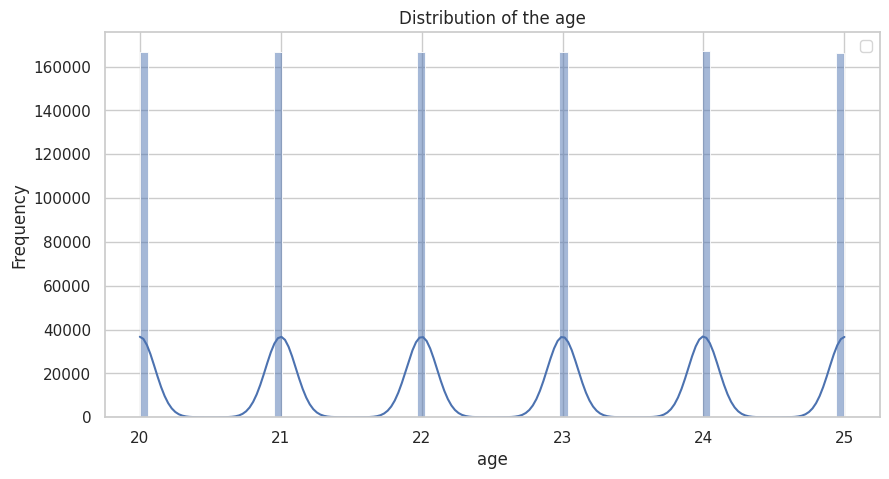

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


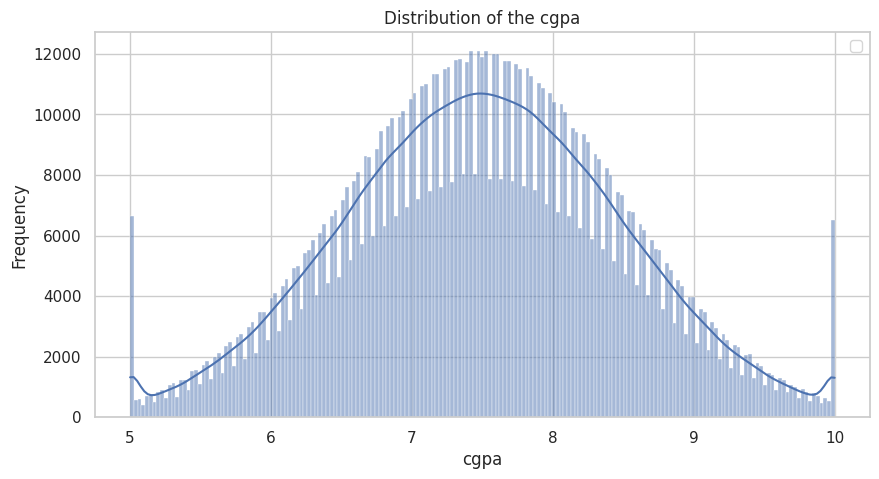

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


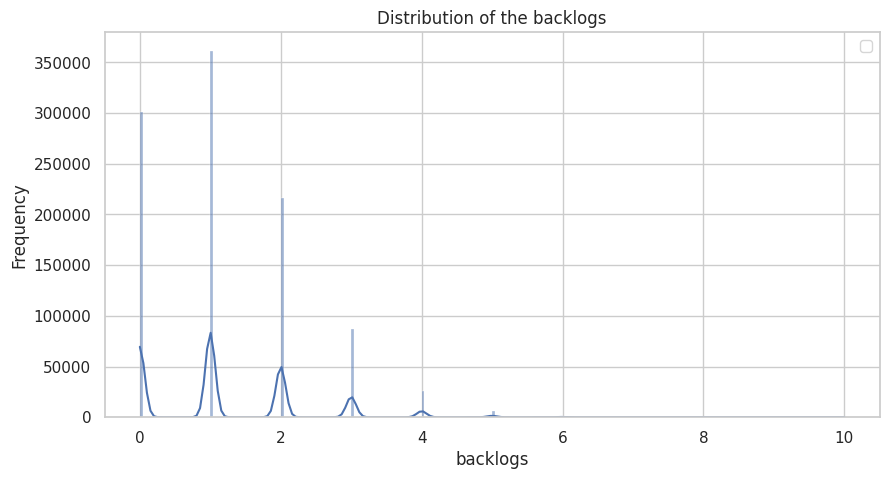

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


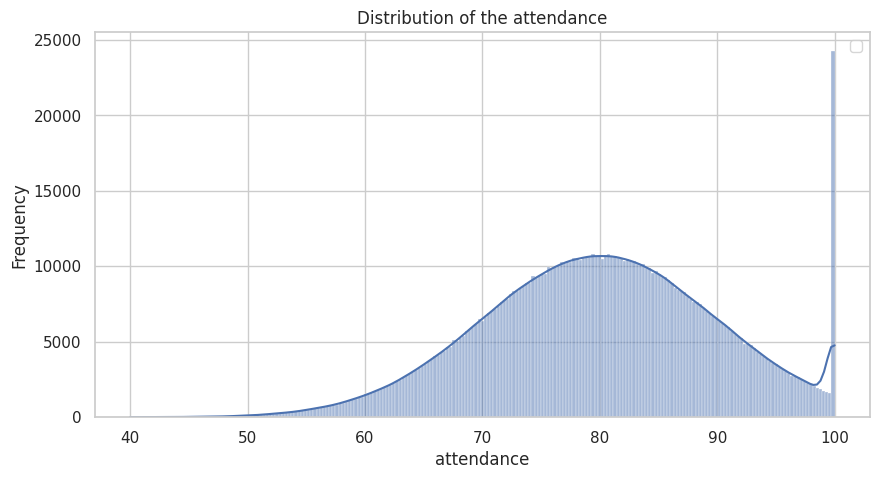

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


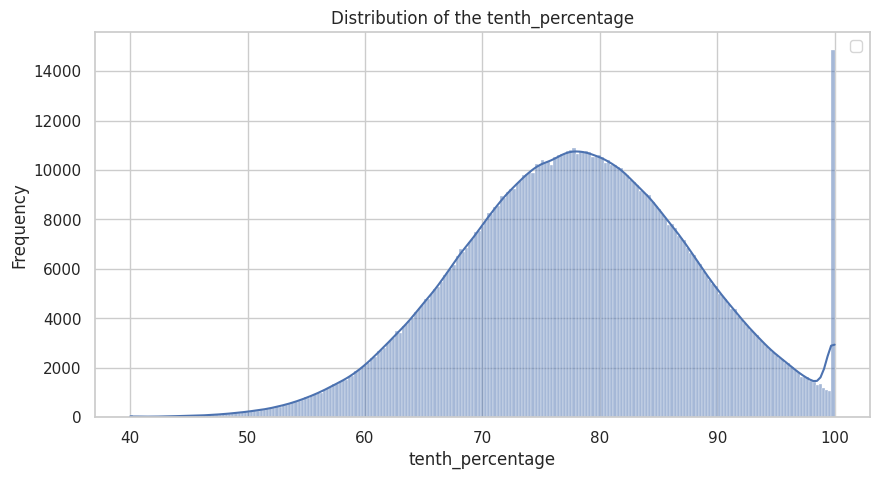

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


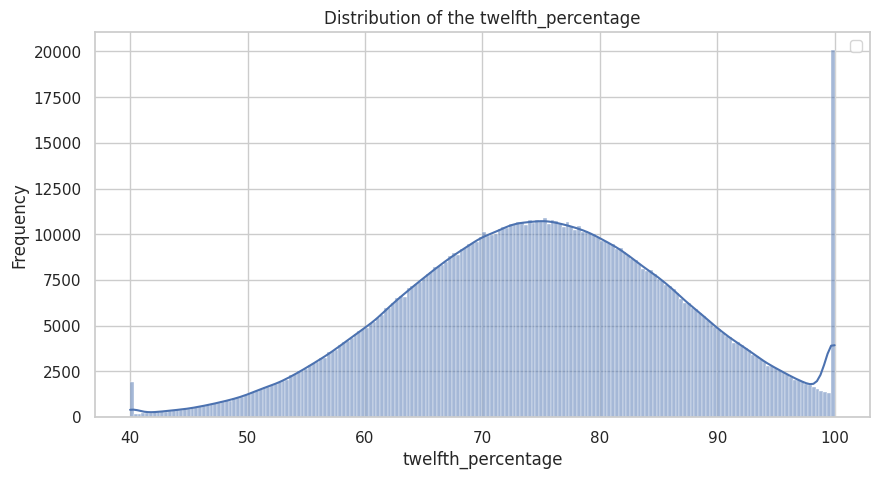

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


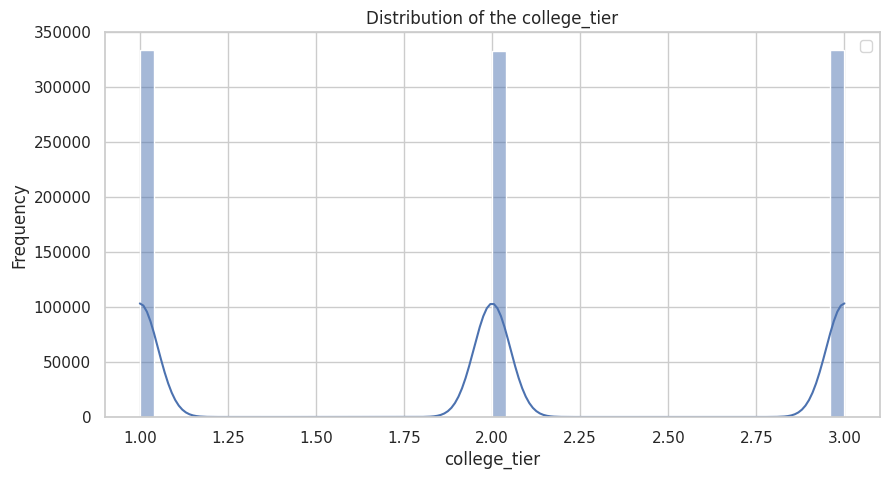

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


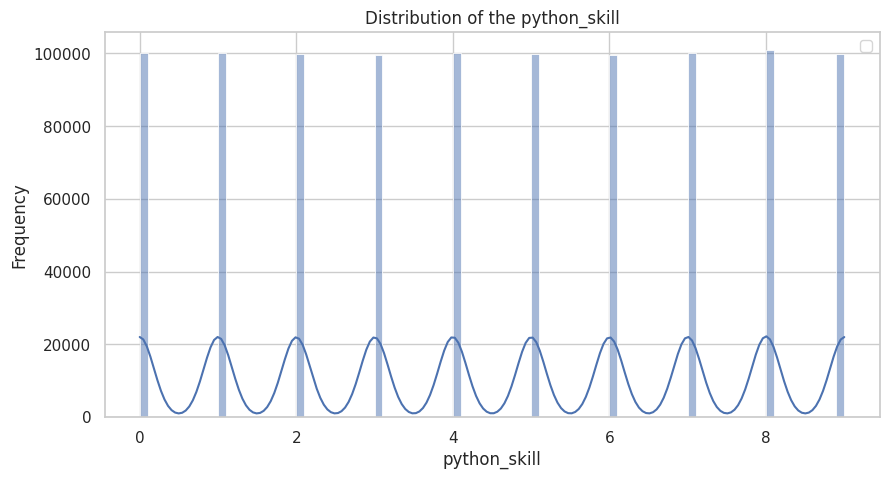

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


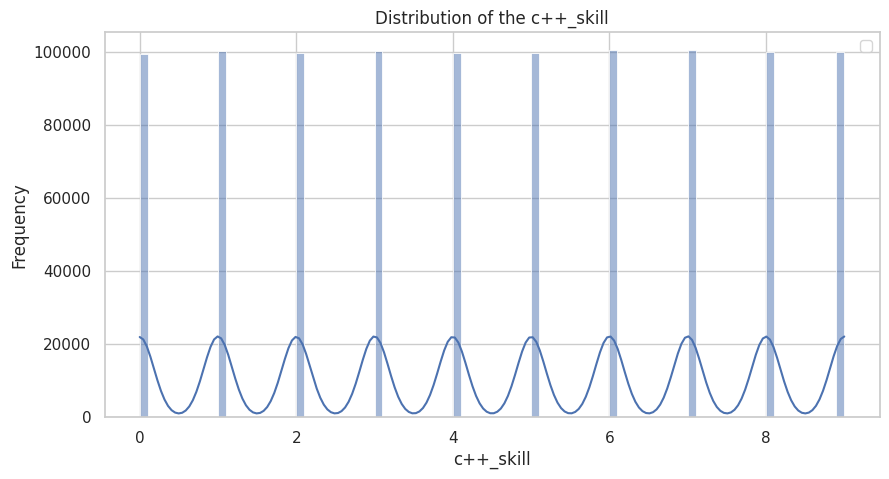

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


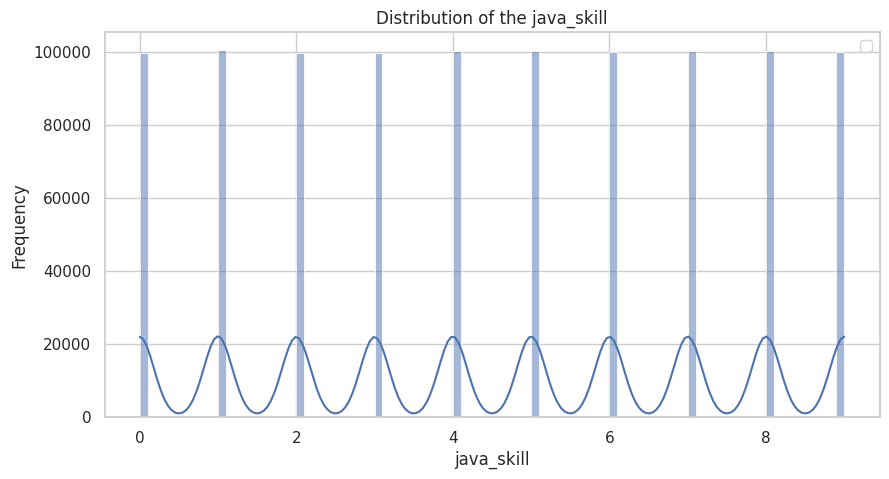

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


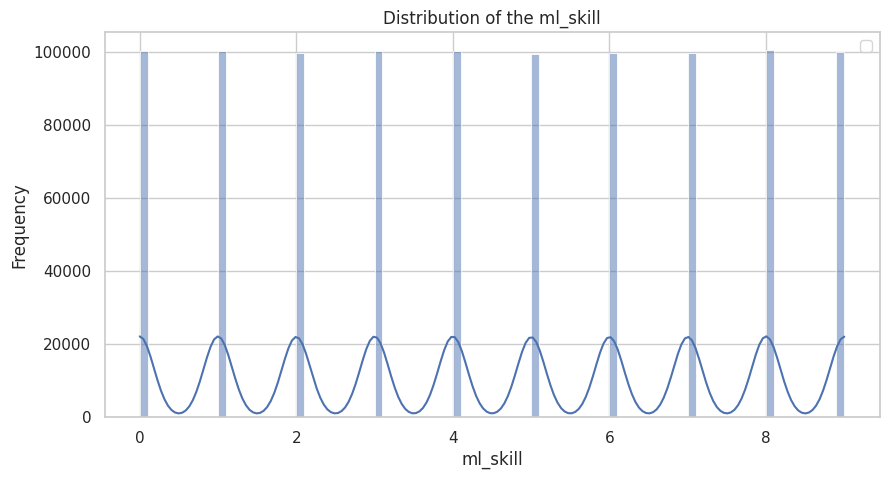

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


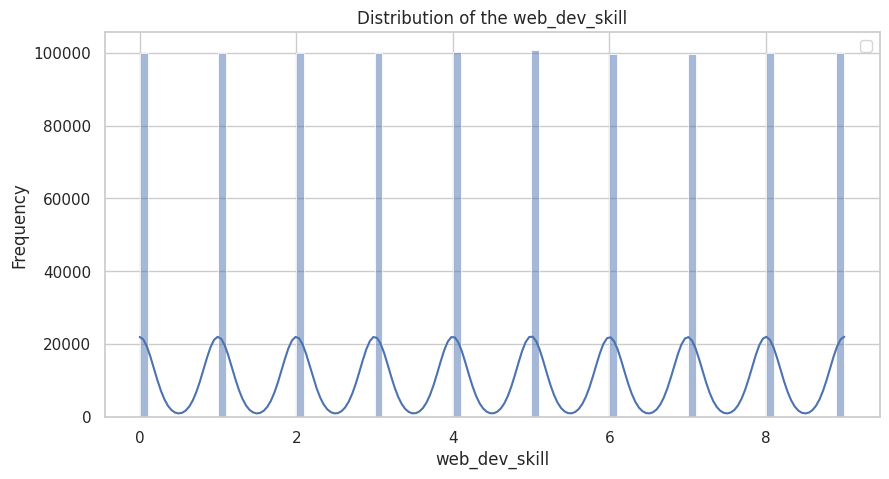

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


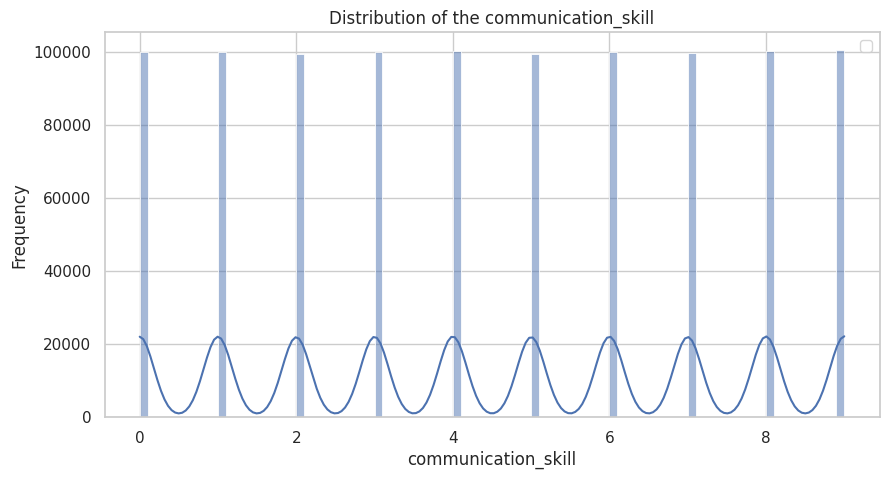

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


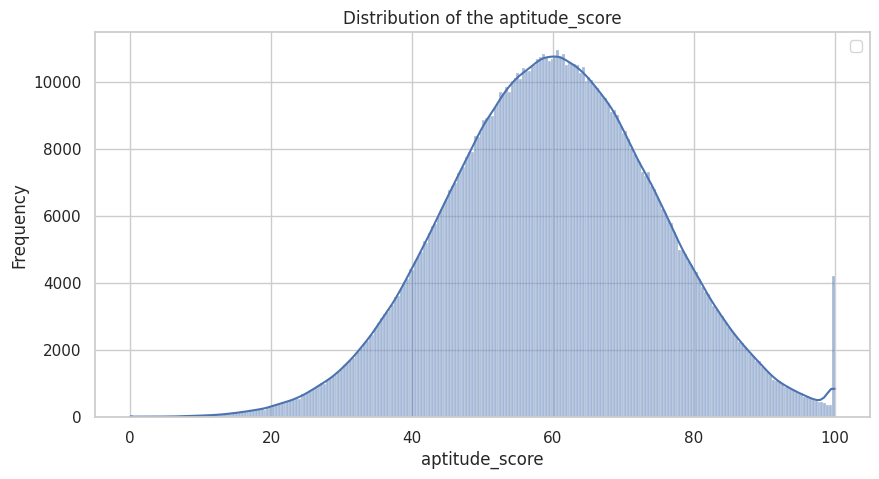

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


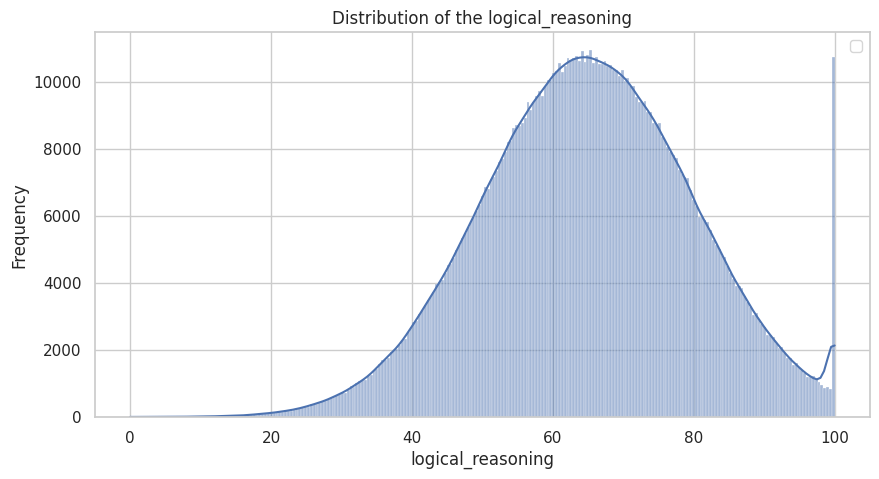

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


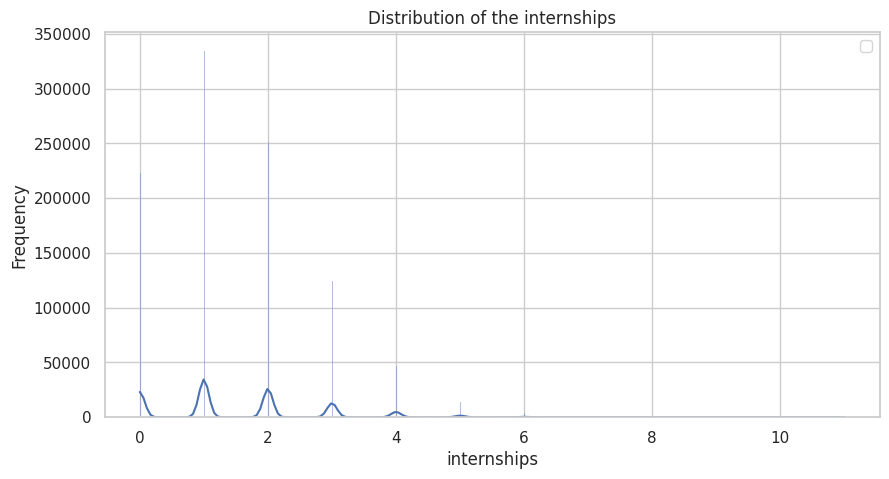

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


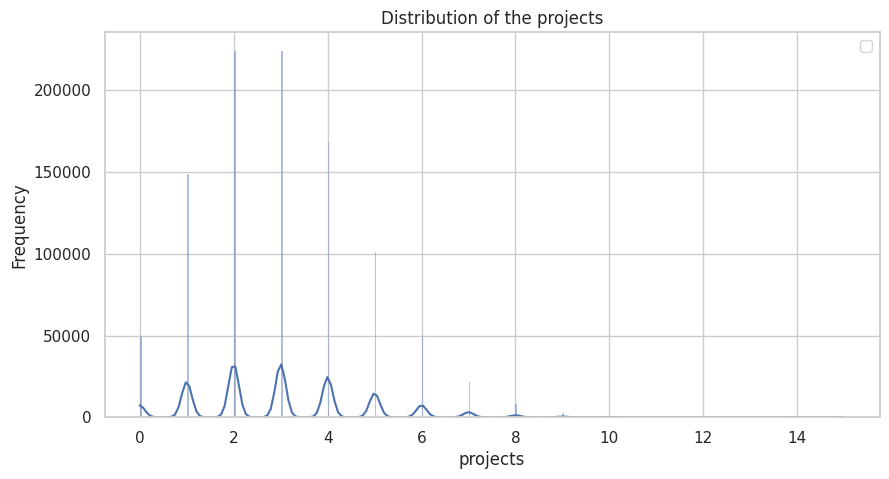

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


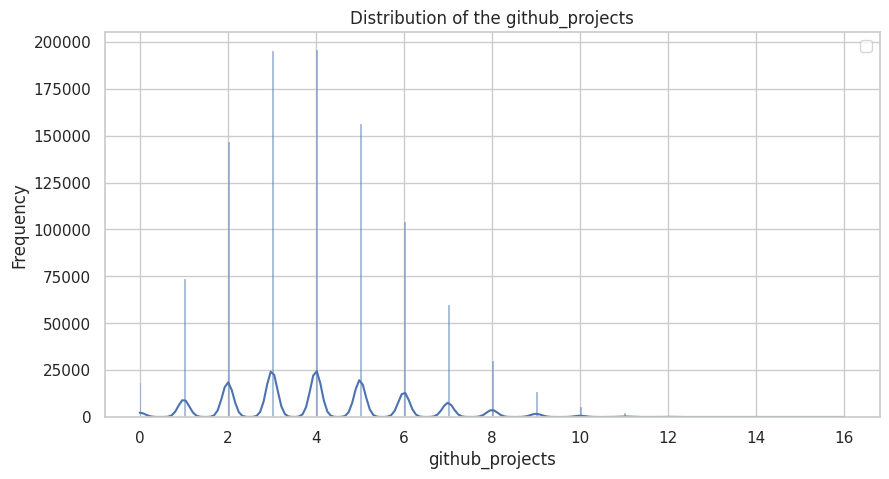

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


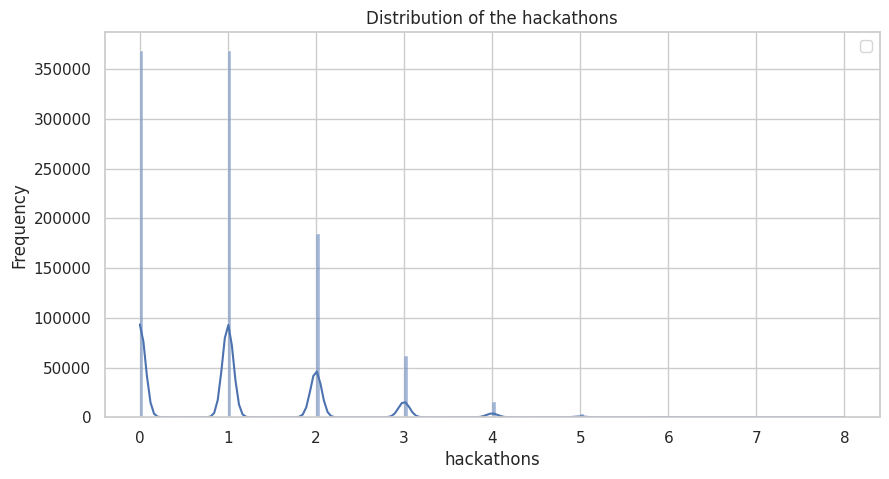

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


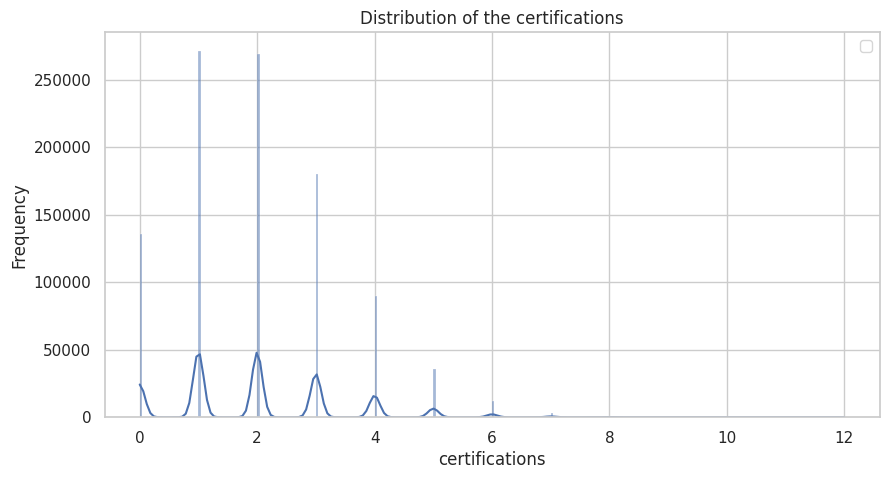

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


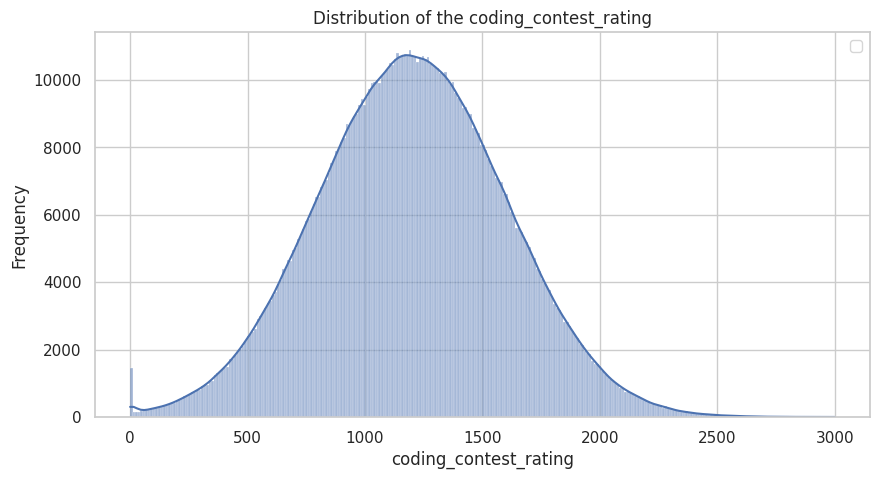

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


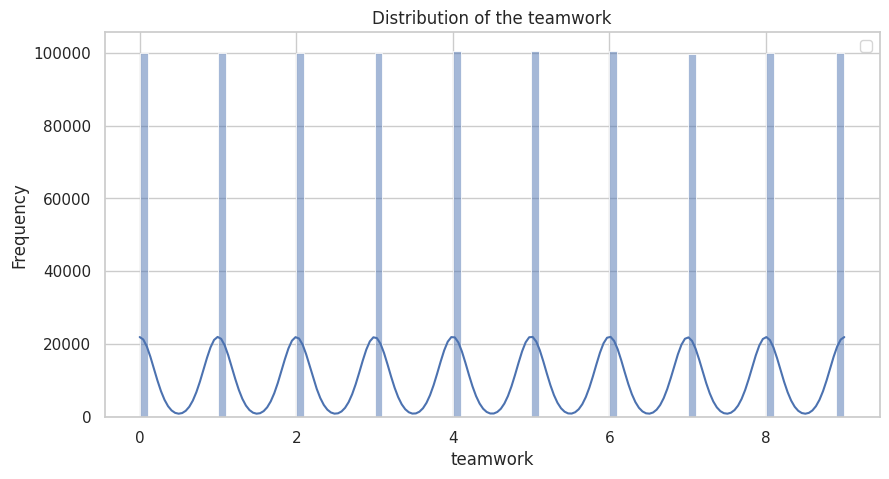

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


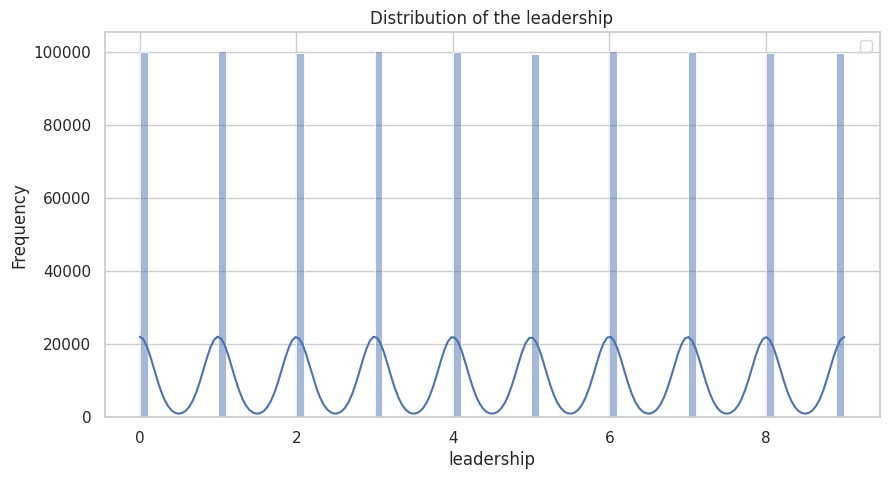

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


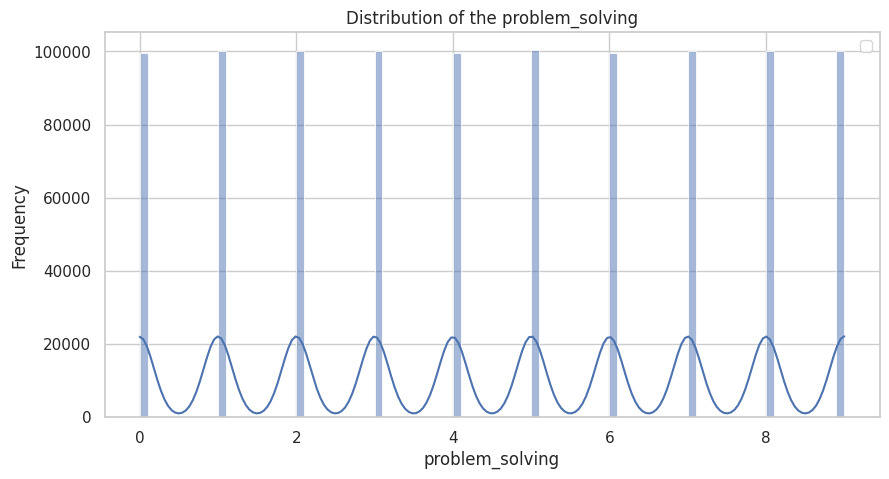

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


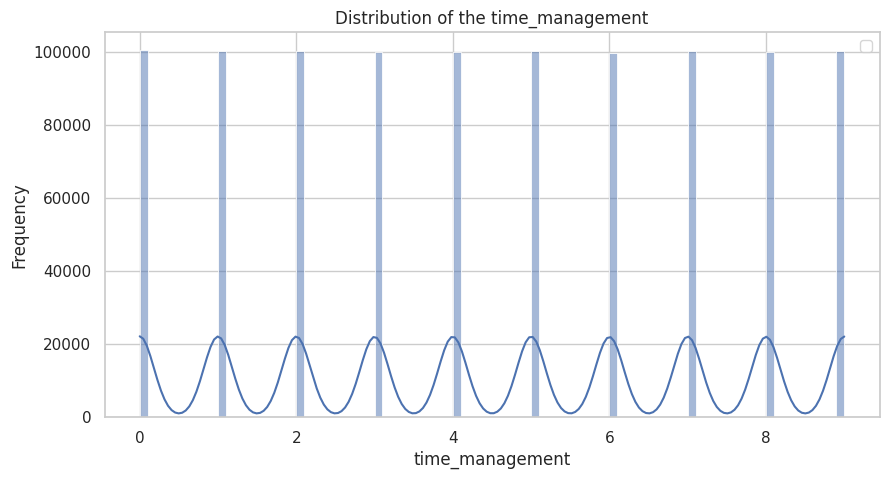

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


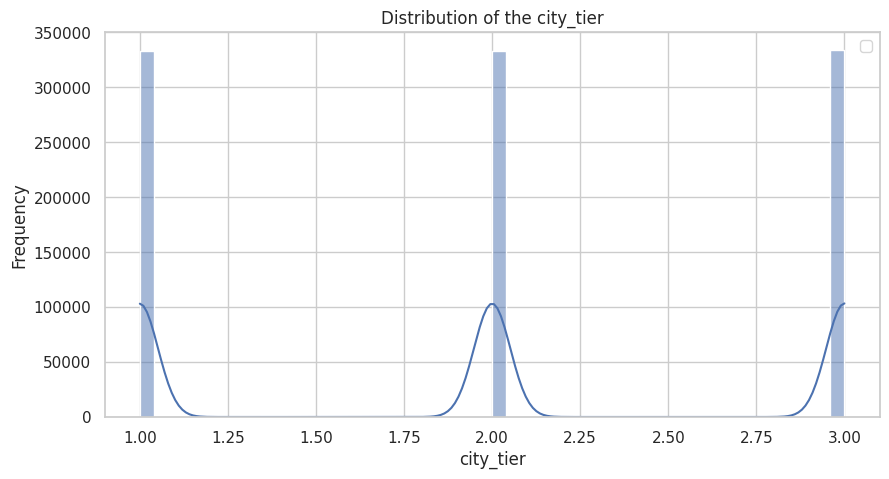

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


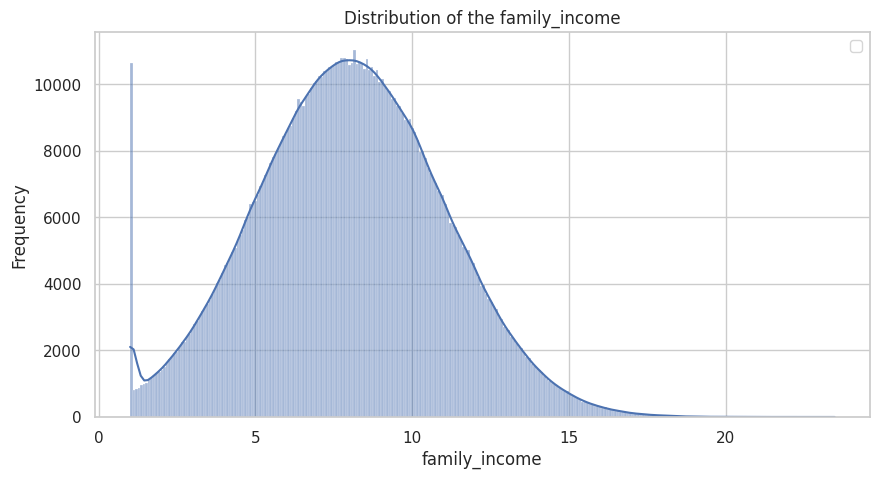

/tmp/ipykernel_17884/2535175683.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


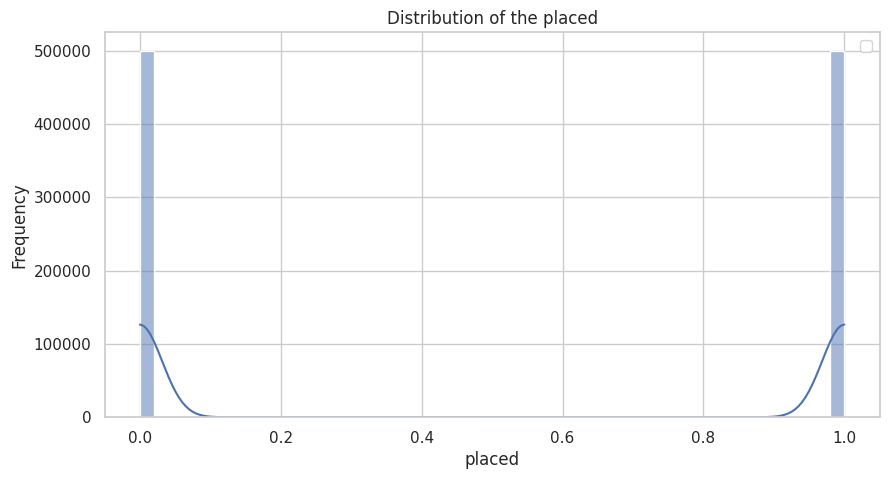

In [44]:
# lets find the insight of the data using the visualization
columns = ['age', 'cgpa', 'backlogs', 'attendance', 'tenth_percentage',
       'twelfth_percentage', 'college_tier', 'python_skill', 'c++_skill',
       'java_skill', 'ml_skill', 'web_dev_skill', 'communication_skill',
       'aptitude_score', 'logical_reasoning', 'internships', 'projects',
       'github_projects', 'hackathons', 'certifications',
       'coding_contest_rating', 'teamwork', 'leadership', 'problem_solving',
       'time_management', 'city_tier', 'family_income', 'placed']

for col in columns:
  fig = plt.figure(figsize=(10,5))
  sns.histplot(df1[col],kde=True)

  plt.title(f"Distribution of the {col}")
  plt.xlabel(f"{col}")
  plt.ylabel("Frequency")
  plt.legend()
  plt.show()

# analysis the Intership vs placement

/tmp/ipykernel_17884/2467070252.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='internships', y='placed', data=df, ax=ax1, errorbar=None, palette='Blues_d')


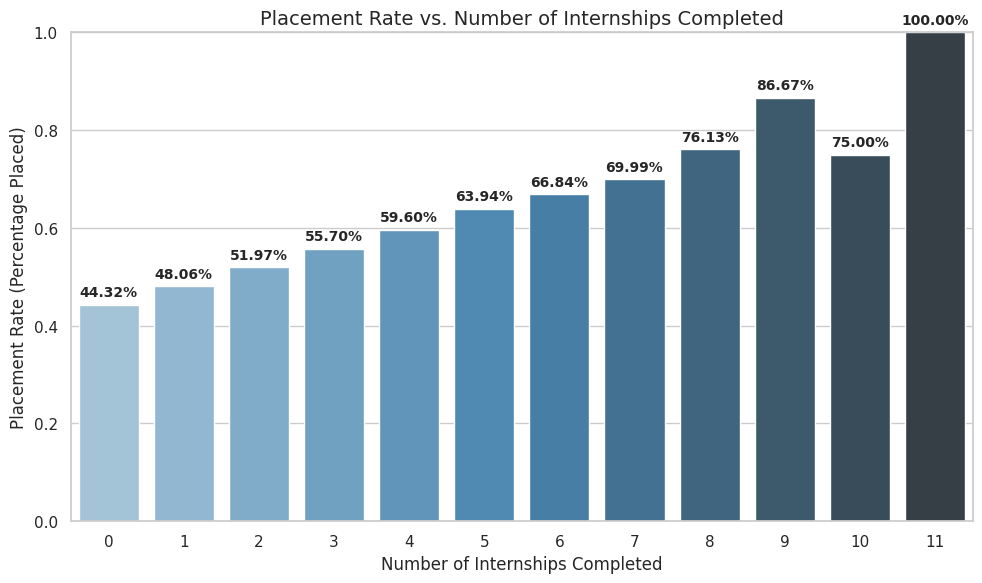

In [45]:

# Set style
sns.set_theme(style="whitegrid")

# Create a plot showing placement rate by number of internships
fig, ax1 = plt.subplots(figsize=(10, 6))

sns.barplot(x='internships', y='placed', data=df, ax=ax1, errorbar=None, palette='Blues_d')
ax1.set_title('Placement Rate vs. Number of Internships Completed', fontsize=14)
ax1.set_xlabel('Number of Internships Completed', fontsize=12)
ax1.set_ylabel('Placement Rate (Percentage Placed)', fontsize=12)
ax1.set_ylim(0, 1.0)

# Annotate bars with the exact percentage
for p in ax1.patches:
    ax1.annotate(f"{p.get_height()*100:.2f}%",
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center',
                 xytext=(0, 9),
                 textcoords='offset points',
                 fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Github_project vs Placed**

/tmp/ipykernel_17884/2024006352.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='github_projects', y='placed', data=df,errorbar=None ,ax=ax1, palette='rocket')


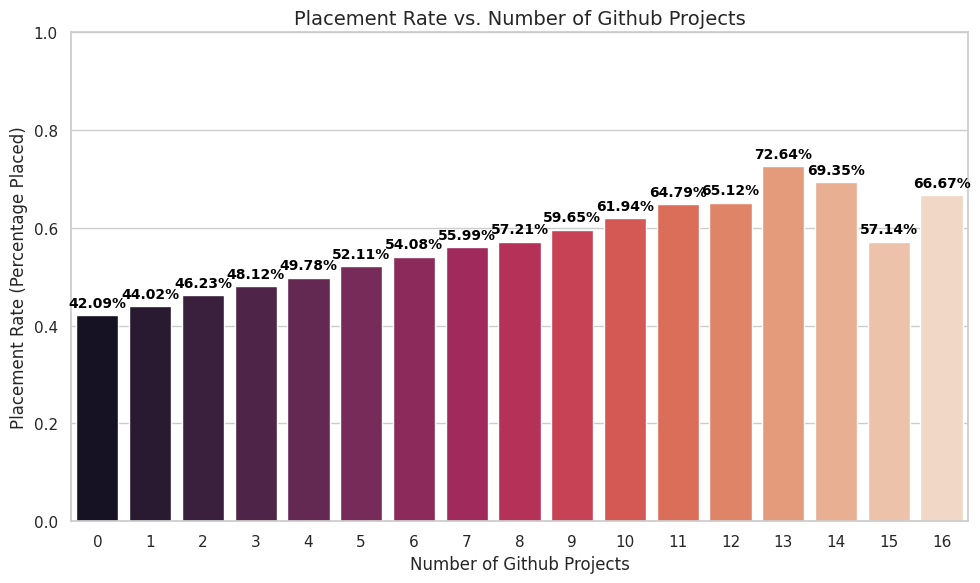

In [46]:
# Visual theam :
sns.set_theme(style="whitegrid")

# Create a fig of the graph
fig,ax1 = plt.subplots(figsize=(10,6))

# Plot the barplot
# Pass the dataframe (df) and specify column names for x and y
# ax=ax1 ensures the plot draws directly onto the canvas we created above
sns.barplot(x='github_projects', y='placed', data=df,errorbar=None ,ax=ax1, palette='rocket')

ax1.set_title('Placement Rate vs. Number of Github Projects', fontsize=14)
ax1.set_xlabel('Number of Github Projects', fontsize=12)
ax1.set_ylabel('Placement Rate (Percentage Placed)', fontsize=12)

ax1.set_ylim(0, 1.0)

# Loop through every individual bar in the plot
for p in ax1.patches:
    # 1. Calculate the Y-value (height) as a percentage string
    percentage_text = f"{p.get_height() * 100:.2f}%"

    # 2. Find the exact horizontal middle of the current bar
    x_coordinate = p.get_x() + p.get_width() / 2.

    # 3. Find the exact vertical top of the current bar
    y_coordinate = p.get_height()

    # 4. Place the text at those coordinates
    ax1.annotate(percentage_text,
                 (x_coordinate, y_coordinate),
                 ha='center', va='center',          # Center align the text horizontally and vertically
                 xytext=(0, 9),                     # Shift the text 9 points up so it doesn't touch the bar line
                 textcoords='offset points',        # Tells Python that (0, 9) is a pixel offset, not data coordinates
                 fontsize=10, fontweight='bold', # Style the font
                 color = 'Black')

plt.tight_layout() # Adjusts layout margins so no labels get clipped out
plt.show()         # Renders the final image on your screen



**Projects vs Placed**

/tmp/ipykernel_17884/2032511932.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='projects', y='placed', data=df, ax=ax1, errorbar=None, palette='magma')


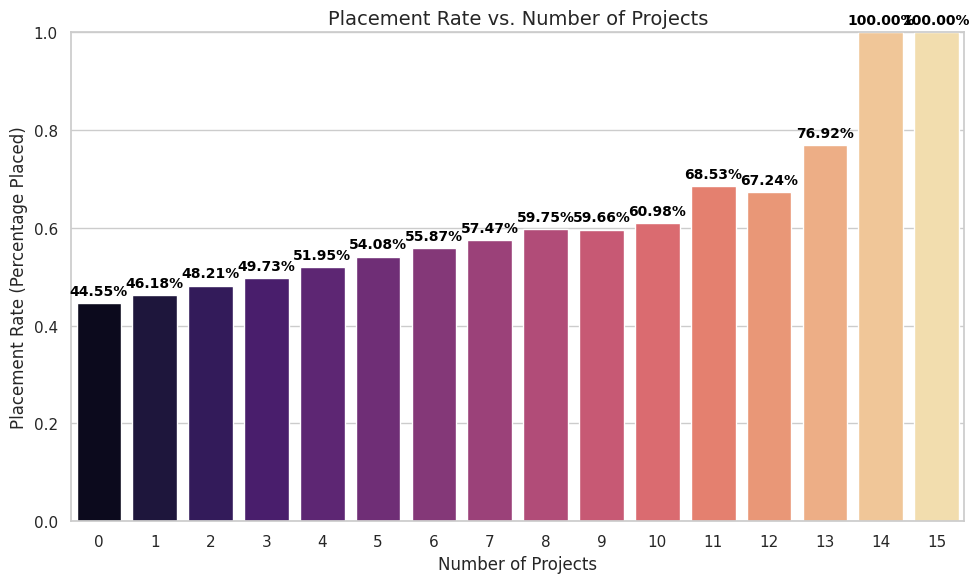

In [47]:
# set the theam of the plot
sns.set_theme(style="whitegrid")

# Create a fig of the graph
fig,ax1 = plt.subplots(figsize=(10,6))

# Plot the barplot

sns.barplot(x='projects', y='placed', data=df, ax=ax1, errorbar=None, palette='magma')

ax1.set_title('Placement Rate vs. Number of Projects', fontsize=14)
ax1.set_xlabel('Number of Projects', fontsize=12)
ax1.set_ylabel('Placement Rate (Percentage Placed)', fontsize=12)

ax1.set_ylim(0, 1.0)

# Loop through every individual bar in the plot
for p in ax1.patches:
  # calculate the y height in the percentage
  percentage_text = f"{p.get_height() * 100:.2f}%"

  # Find the exact horizontal middle of the current bar
  x_coordinate = p.get_x() + p.get_width() /2.

  # vertical top current bar
  y_coordinate = p.get_height()

  # Place the text at those coordinates
  ax1.annotate(percentage_text,
                 (x_coordinate, y_coordinate),
                 ha='center', va='center',          # Center align the text horizontally and vertically
                 xytext=(0,9),
                 textcoords='offset points',        # Tells Python that (0, 9) is a pixel offset, not data coordinates
                 fontsize=10, fontweight='bold', # Style the font
                 color = 'Black')

  ax1.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()

** coding_contest_rating vs placement**

/tmp/ipykernel_17884/3012044245.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x='certifications', y='placed', data=df, ax=ax1, errorbar=None, palette='rocket')


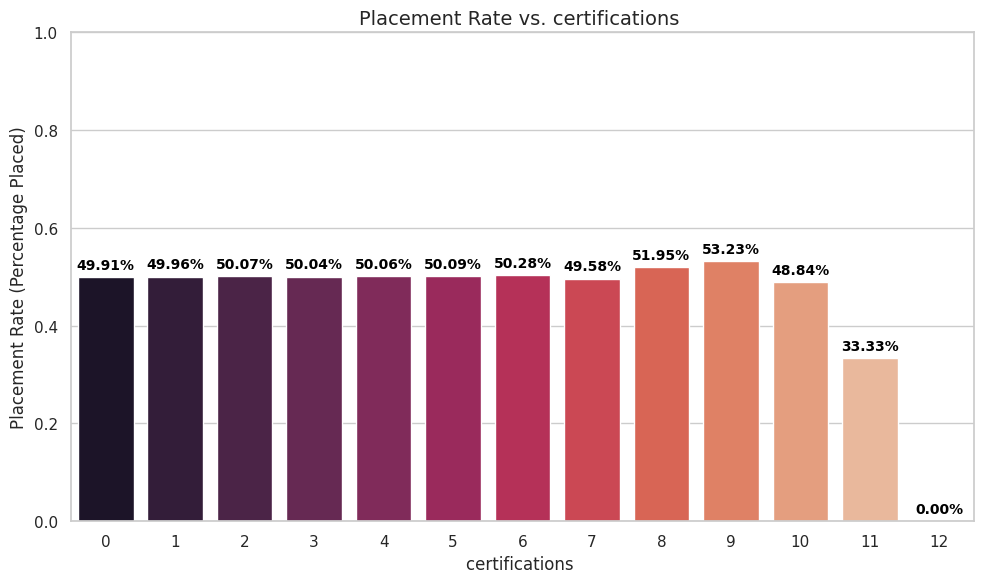

In [48]:
sns.set_theme(style="whitegrid")

# Create a fig of the graph
fig,ax1 = plt.subplots(figsize=(10,6))

# Plot the barplot
ax3 = sns.barplot(x='certifications', y='placed', data=df, ax=ax1, errorbar=None, palette='rocket')

ax1.set_title('Placement Rate vs. certifications ', fontsize=14)
ax1.set_xlabel('certifications ', fontsize=12)
ax1.set_ylabel('Placement Rate (Percentage Placed)', fontsize=12)

ax1.set_ylim(0, 1.0)

# Loop through every individual bar in the plot
for p in ax1.patches:
  # calculate the y height in the percentage
  percentage_text = f"{p.get_height() * 100:.2f}%"

  # Find the exact horizontal middle of the current bar
  x_coordinate = p.get_x() + p.get_width() /2.

  # vertical top current bar
  y_coordinate = p.get_height()

  # Place the text at those coordinates
  ax1.annotate(percentage_text,
                 (x_coordinate, y_coordinate),
                 ha='center', va='center',          # Center align the text horizontally and vertically
                 xytext=(0,9),
                 textcoords='offset points',        # Tells Python that (0, 9) is a pixel offset, not data coordinates
                 fontsize=10, fontweight='bold', # Style the font
                 color = 'Black')

  ax1.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


/tmp/ipykernel_17884/1446518122.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(x='branch', y='placed', data=df, ax=ax1, errorbar=None, palette='rocket')


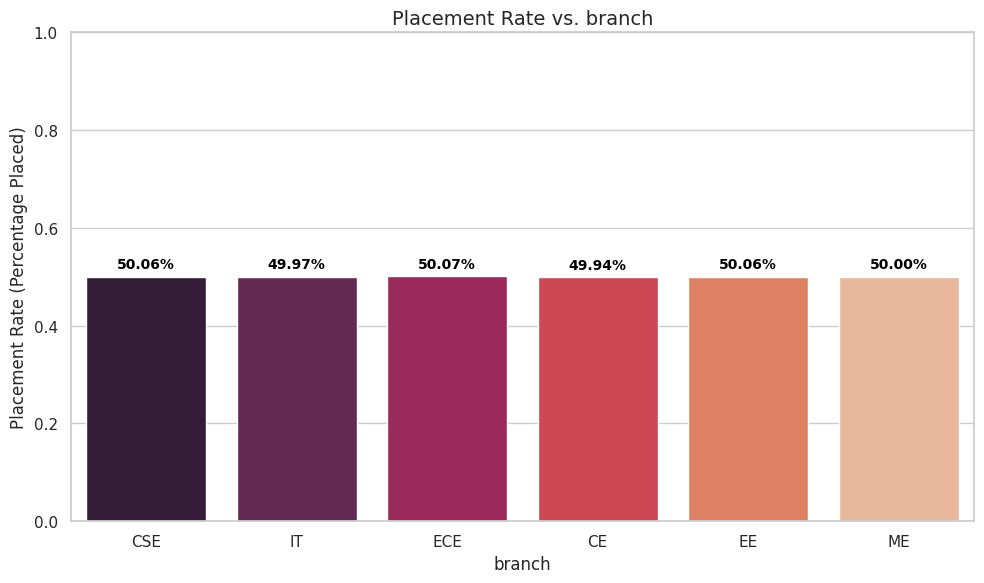

In [49]:
sns.set_theme(style="whitegrid")

# Create a fig of the graph
fig,ax1 = plt.subplots(figsize=(10,6))

# Plot the barplot
ax3 = sns.barplot(x='branch', y='placed', data=df, ax=ax1, errorbar=None, palette='rocket')

ax1.set_title('Placement Rate vs. branch', fontsize=14)
ax1.set_xlabel('branch', fontsize=12)
ax1.set_ylabel('Placement Rate (Percentage Placed)', fontsize=12)

ax1.set_ylim(0, 1.0)

# Loop through every individual bar in the plot
for p in ax1.patches:
  # calculate the y height in the percentage
  percentage_text = f"{p.get_height() * 100:.2f}%"

  # Find the exact horizontal middle of the current bar
  x_coordinate = p.get_x() + p.get_width() /2.

  # vertical top current bar
  y_coordinate = p.get_height()

  # Place the text at those coordinates
  ax1.annotate(percentage_text,
                 (x_coordinate, y_coordinate),
                 ha='center', va='center',          # Center align the text horizontally and vertically
                 xytext=(0,9),
                 textcoords='offset points',        # Tells Python that (0, 9) is a pixel offset, not data coordinates
                 fontsize=10, fontweight='bold', # Style the font
                 color = 'Black')

  ax1.set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


**Iqr**

In [50]:
comparison = []
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()


for col in numerical_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    comparison.append({
        'Feature': col,

        'IQR_Outliers': iqr_count
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.sort_values(
    by='IQR_Outliers',
    ascending=False
))

                  Feature  IQR_Outliers
15            internships         65596
17        github_projects         21396
16               projects         12070
20  coding_contest_rating          6785
19         certifications          4588
4        tenth_percentage          3506
5      twelfth_percentage          3498
13         aptitude_score          3464
26          family_income          3459
14      logical_reasoning          3423
3              attendance          3420
2                backlogs          1501
18             hackathons           617
10               ml_skill             0
9              java_skill             0
8               c++_skill             0
7            python_skill             0
6            college_tier             0
1                    cgpa             0
0                     age             0
11          web_dev_skill             0
12    communication_skill             0
22             leadership             0
21               teamwork             0


In [61]:
import pandas as pd
import numpy as np

# Store original dataset
df_clean = df.copy()

# Select numerical features
numerical_features = df.select_dtypes(
    include=['float64', 'int64']
).columns.tolist()

comparison = []

# Remove outliers feature by feature
for col in numerical_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Count outliers before removal
    outlier_count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    # Remove outlier rows
    df_clean = df_clean[
        (df_clean[col] >= lower) &
        (df_clean[col] <= upper)
    ]

    comparison.append({
        'Feature': col,
        'IQR_Outliers_Removed': outlier_count
    })

# Create comparison dataframe
comparison_df = pd.DataFrame(comparison)

print("Outlier Removal Report:")
print(comparison_df.sort_values(
    by='IQR_Outliers_Removed',
    ascending=False
))

# Dataset comparison
print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)
print("Total Rows Removed:", len(df) - len(df_clean))
print("Remaining Rows:", len(df_clean))

Outlier Removal Report:
                          Feature  IQR_Outliers_Removed
4                tenth_percentage                  3488
5              twelfth_percentage                  3474
3                      attendance                  3416
2                        backlogs                  1501
0                             age                     0
1                            cgpa                     0
6                          branch                     0
7                    college_tier                     0
8                    python_skill                     0
9                       c++_skill                     0
10                     java_skill                     0
11                       ml_skill                     0
12                  web_dev_skill                     0
13            communication_skill                     0
14                 aptitude_score                     0
15              logical_reasoning                     0
16                    in

# Feature Engineering

**Method 1: Correlation**

In [62]:

df1.corr()['placed']

,placed
age,0.000194
cgpa,0.115080
backlogs,-0.041069
attendance,-0.000306
tenth_percentage,0.000730
twelfth_percentage,-0.000296
college_tier,0.000531
python_skill,0.139277
c++_skill,0.138423
java_skill,0.140398


**Insight**
* Here is the feature corr. with the  placed is not helpful to decide the best feature .
* As per the working of the corr. it not affect the other columns it work only on the target columns and columns
* Correlation looks for patterns in data points and gives you a single number between -1.0 and +1.0. This number is called the Correlation Coefficient (r).

**Method 2: Embedded**

1.Random Forest

In [84]:
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier

x = df.drop('placed', axis=1)
y = df['placed']

# Instantiate the classifier with a random state
model = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=1)

# Instantiate SelectFromModel
sfm = SelectFromModel(model)

# Fit the selector to the dataset
sfm.fit(x, y)

# Display selected features
selected_features = x.columns[sfm.get_support()]
print("Selected Features:", list(selected_features))

Selected Features: ['attendance', 'tenth_percentage', 'twelfth_percentage', 'python_skill', 'c++_skill', 'java_skill', 'ml_skill', 'web_dev_skill', 'aptitude_score', 'logical_reasoning', 'coding_contest_rating', 'teamwork', 'problem_solving', 'family_income', 'Skills', 'Soft_Skills', 'Marks']


Method 2: Xgboost

In [83]:
from sklearn.feature_selection import SelectFromModel
from xgboost import XGBClassifier

x = df.drop('placed', axis=1)
y = df['placed']

# Instantiate the classifier with a random state
model = XGBClassifier(random_state=42)

# Instantiate SelectFromModel
sfm = SelectFromModel(model)

# Fit the selector to the dataset
sfm.fit(x, y)

xgboost_feature = x.columns[sfm.get_support()]
print("Selected Features:", list(xgboost_feature))

Selected Features: ['backlogs', 'internships', 'hackathons', 'teamwork', 'leadership', 'problem_solving', 'Skills', 'Soft_Skills', 'total_projects_and_hackathons']


# Feature Selection


In [54]:
df['branch'].unique()

array(['CSE', 'IT', 'ECE', 'CE', 'EE', 'ME'], dtype=object)

In [60]:
# lest encode the gender and branch
df['gender'] = df['gender'].map({'M': 0, 'F': 1})
# for the branch
df['branch'] = df['branch'].map({'CSE':0,'IT':1,'ECE':2,'ME':3,'CE':4,'EE':5})


In [87]:
# Re-load or reference df to make sure we don't carry over corrupted constant columns
# Let's clean up and define correct engineered features keeping variance per row

# Group Skills by summing them up for each student
df['Skills'] = df[
    ['python_skill', 'c++_skill', 'java_skill',
     'ml_skill', 'web_dev_skill']
].mean(axis=1)

# Soft Skills sum
df['Soft_Skills'] = df[['logical_reasoning','aptitude_score','communication_skill']].mean(axis =1)

# Marks sum
df['Marks'] = df[['tenth_percentage','twelfth_percentage']].mean(axis =1)

# Campus and Region Tier sum
df['campus_region_Tier'] = df[['college_tier','city_tier']].mean(axis =1)

# Projects and hackathons sum
df['total_projects_and_hackathons'] = df[['github_projects','projects','hackathons']].mean(axis =1)

# Let's keep CGPA as its original distribution rather than destroying it,
# or if we want a combined feature we sum them:
df['cgpa_and_leadership'] = df[['cgpa','leadership']].mean(axis =1)

In [79]:
df.corr()['placed']

,placed
age,0.000194
cgpa,NaN
backlogs,-0.041069
attendance,-0.000306
tenth_percentage,0.000730
twelfth_percentage,-0.000296
branch,NaN
college_tier,0.000531
python_skill,0.139277
c++_skill,0.138423


In [90]:
# Calculate correlation with 'placed'
corr_matrix = df.corr()['placed']

# Let's filter features with correlation magnitude greater than a threshold
# Since no features exceed 0.50 (50%), let's list them sorted by absolute correlation
threshold = 0.05 # You can change this to 0.50, 0.10, etc.

high_corr_features = corr_matrix[abs(corr_matrix) > threshold].sort_values(ascending=False)

print(f"Features with correlation absolute value > {threshold}:")
display(high_corr_features)

Features with correlation absolute value > 0.05:


,placed
placed,1.000000
super_placement_score,0.330388
Skills,0.309971
java_skill,0.140398
python_skill,0.139277
c++_skill,0.138423
web_dev_skill,0.138010
ml_skill,0.137330
Soft_Skills,0.120109
total_projects_and_hackathons,0.103702


In [88]:
from sklearn.preprocessing import StandardScaler

# Let's select the features that already show positive correlation with 'placed'
top_features = [
    'Skills',
    'internships',
    'total_projects_and_hackathons',
    'Soft_Skills',
    'teamwork',
    'problem_solving',
    'leadership'
]

# Scale the features first so they contribute equally
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[top_features])

# Combine them by summing up the scaled representations
# (We can also apply weights based on their individual correlation values if needed)
df['super_placement_score'] = scaled_features.sum(axis=1)

# Calculate and print the correlation of the new combined feature with 'placed'
new_corr = df.corr()['placed']['super_placement_score']
print(f"Correlation of 'super_placement_score' with 'placed': {new_corr:.4f}")

Correlation of 'super_placement_score' with 'placed': 0.3304


In [89]:
from sklearn.preprocessing import StandardScaler

# Define the best positively correlating features
top_features = [
    'Skills',
    'internships',
    'total_projects_and_hackathons',
    'Soft_Skills',
    'teamwork',
    'problem_solving',
    'leadership'
]

# Scale the features so they have comparable variance and scale
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[top_features])

# Combine the scaled values by summing them across columns
df['super_placement_score'] = scaled_features.sum(axis=1)

# Compute correlation of the combined feature with the target 'placed'
new_corr = df.corr()['placed']['super_placement_score']
print(f"Correlation of 'super_placement_score' with 'placed': {new_corr:.4f}")

Correlation of 'super_placement_score' with 'placed': 0.3304


/tmp/ipykernel_17884/4028347481.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='placed', y='super_placement_score', data=df, ax=axes[0], palette='Set2')


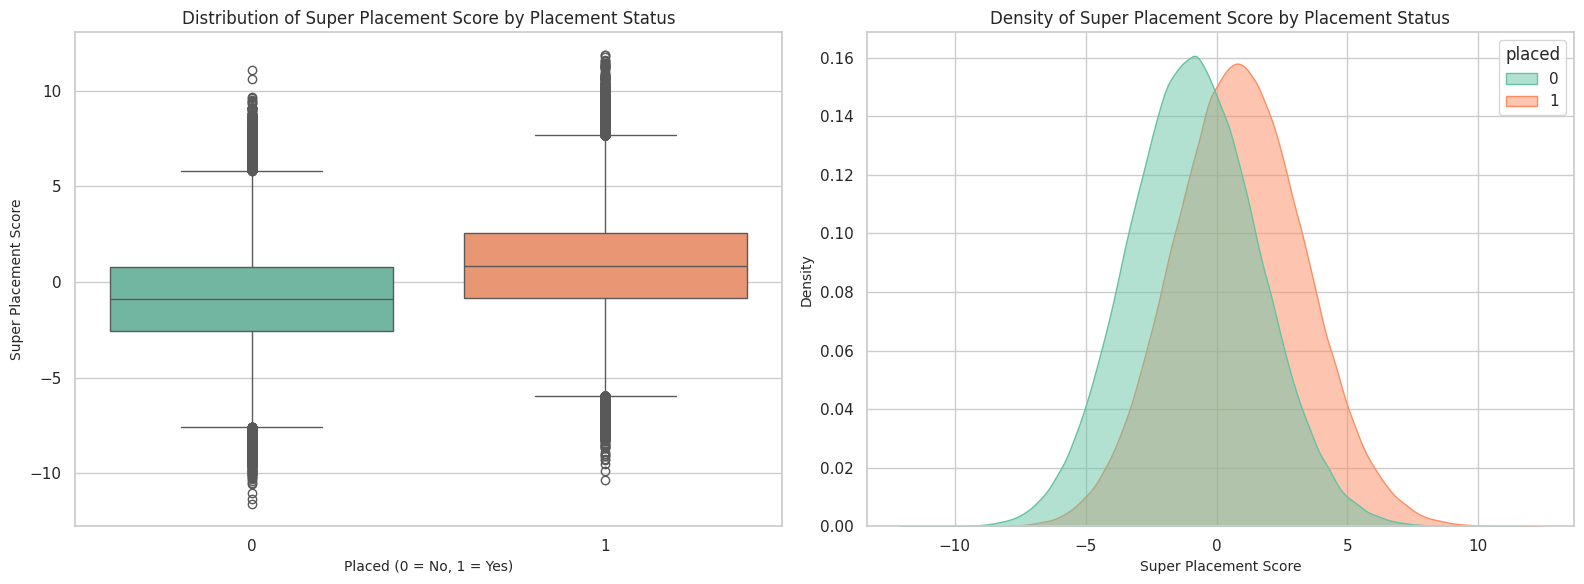

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style="whitegrid")

# Create a figure with two subplots: a Boxplot and a KDE distribution plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot
sns.boxplot(x='placed', y='super_placement_score', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Distribution of Super Placement Score by Placement Status', fontsize=12)
axes[0].set_xlabel('Placed (0 = No, 1 = Yes)', fontsize=10)
axes[0].set_ylabel('Super Placement Score', fontsize=10)

# 2. KDE Plot
sns.kdeplot(data=df, x='super_placement_score', hue='placed', fill=True, common_norm=False, alpha=0.5, palette='Set2', ax=axes[1])
axes[1].set_title('Density of Super Placement Score by Placement Status', fontsize=12)
axes[1].set_xlabel('Super Placement Score', fontsize=10)
axes[1].set_ylabel('Density', fontsize=10)

plt.tight_layout()
plt.show()

In [92]:
from sklearn.model_selection import train_test_split

# Select our best feature columns based on correlation and feature selection steps
selected_model_features = [
    'super_placement_score',
    'Skills',
    'Soft_Skills',
    'total_projects_and_hackathons',
    'internships',
    'teamwork',
    'problem_solving',
    'leadership'
]

# Define X and y
X = df[selected_model_features]
y = df['placed']

# Split into 70% Train and 30% Temporary (to be split into Val and Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split the remaining 30% equally into Validation (15%) and Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Print shapes to verify
print("Data Splitting Results:")
print(f"Training set:   {X_train.shape} | Labels: {y_train.shape}")
print(f"Validation set: {X_val.shape} | Labels: {y_val.shape}")
print(f"Testing set:    {X_test.shape}  | Labels: {y_test.shape}")

Data Splitting Results:
Training set:   (700000, 8) | Labels: (700000,)
Validation set: (150000, 8) | Labels: (150000,)
Testing set:    (150000, 8)  | Labels: (150000,)


# model Selection

In [93]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Define the hyperparameter search space
param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 8, 12, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Instantiate base Random Forest Classifier
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Run RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=5,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Randomized Hyperparameter Search on training subset...")
# Fit on a subset first for rapid tuning (or full set if resources allow)
rf_random_search.fit(X_train, y_train)

# Get the best estimator
best_rf_model = rf_random_search.best_estimator_
print(f"\nBest parameters found: {rf_random_search.best_params_}")

# Evaluate on Validation Set
y_val_pred = best_rf_model.predict(X_val)
y_val_proba = best_rf_model.predict_proba(X_val)[:, 1]

print("\nValidation Classification Report:")
print(classification_report(y_val, y_val_pred))
print(f"Validation ROC-AUC Score: {roc_auc_score(y_val, y_val_proba):.4f}")

Starting Randomized Hyperparameter Search on training subset...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best parameters found: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 12}

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.66      0.66     74976
           1       0.66      0.67      0.67     75024

    accuracy                           0.67    150000
   macro avg       0.67      0.67      0.67    150000
weighted avg       0.67      0.67      0.67    150000

Validation ROC-AUC Score: 0.7254


# method 2 : xg boost

In [95]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Define the hyperparameter search space for XGBoost
param_distributions = {
    'n_estimators': [100, 200,300,400,500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

# Instantiate base XGBoost Classifier
xgb_base = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', n_jobs=-1)

# Run RandomizedSearchCV
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=5,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Randomized Hyperparameter Search for XGBoost...")
xgb_random_search.fit(X_train, y_train)

# Get the best estimator
best_xgb_model = xgb_random_search.best_estimator_
print(f"\nBest XGBoost parameters found: {xgb_random_search.best_params_}")

# Evaluate on Validation Set
y_val_pred_xgb = best_xgb_model.predict(X_val)
super_val_proba_xgb = best_xgb_model.predict_proba(X_val)[:, 1]

print("\nValidation Classification Report (XGBoost):")
print(classification_report(y_val, y_val_pred_xgb))
print(f"Validation ROC-AUC Score (XGBoost): {roc_auc_score(y_val, super_val_proba_xgb):.4f}")

Starting Randomized Hyperparameter Search for XGBoost...
Fitting 3 folds for each of 5 candidates, totalling 15 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [07:24:05] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Best XGBoost parameters found: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.01, 'colsample_bytree': 0.7}

Validation Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.67      0.66      0.66     74976
           1       0.66      0.67      0.67     75024

    accuracy                           0.67    150000
   macro avg       0.67      0.67      0.67    150000
weighted avg       0.67      0.67      0.67    150000

Validation ROC-AUC Score (XGBoost): 0.7260


# method 3 : Neural network

Using device: cpu

Training the Neural Network...
Epoch 01/15 | Train Loss: 0.6164 | Val Loss: 0.6128
Epoch 02/15 | Train Loss: 0.6153 | Val Loss: 0.6113
Epoch 03/15 | Train Loss: 0.6149 | Val Loss: 0.6114
Epoch 04/15 | Train Loss: 0.6150 | Val Loss: 0.6107
Epoch 05/15 | Train Loss: 0.6150 | Val Loss: 0.6124
Epoch 06/15 | Train Loss: 0.6148 | Val Loss: 0.6118
Epoch 07/15 | Train Loss: 0.6149 | Val Loss: 0.6112
Epoch 08/15 | Train Loss: 0.6148 | Val Loss: 0.6113
Epoch 09/15 | Train Loss: 0.6148 | Val Loss: 0.6110
Epoch 10/15 | Train Loss: 0.6149 | Val Loss: 0.6114
Epoch 11/15 | Train Loss: 0.6148 | Val Loss: 0.6110
Epoch 12/15 | Train Loss: 0.6147 | Val Loss: 0.6117
Epoch 13/15 | Train Loss: 0.6147 | Val Loss: 0.6104
Epoch 14/15 | Train Loss: 0.6147 | Val Loss: 0.6116
Epoch 15/15 | Train Loss: 0.6148 | Val Loss: 0.6107


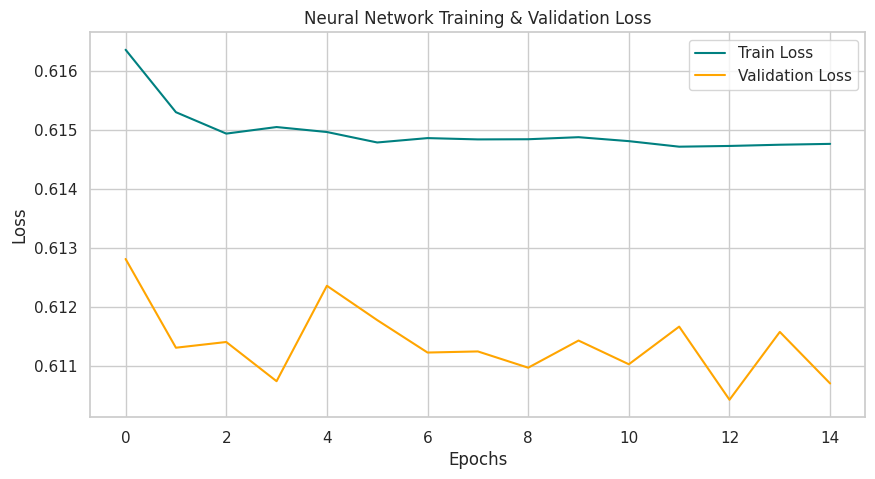

In [96]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

# Set device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Convert DataFrames to PyTorch Tensors
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# Create Datasets and DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Setting batch size to 256 for balanced training speed on 700k records
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

# Define the ANN Architecture
class PlacementANN(nn.Module):
    def __init__(self, input_dim):
        super(PlacementANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x) # Output raw logits (ideal for BCEWithLogitsLoss)

# Initialize model, loss function, and optimizer
model = PlacementANN(input_dim=X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Training Parameters
epochs = 15
train_losses = []
val_losses = []

print("\nTraining the Neural Network...")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation loss
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

# Plot learning curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='teal')
plt.plot(val_losses, label='Validation Loss', color='orange')
plt.title('Neural Network Training & Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [97]:
from sklearn.metrics import accuracy_score, precision_score, classification_report

# Put model in evaluation mode
model.eval()

y_test_pred_list = []

# Predict on the test set using PyTorch DataLoader
with torch.no_grad():
    for batch_X, _ in test_loader:
        batch_X = batch_X.to(device)
        outputs = model(batch_X)
        # Convert raw logits to probabilities, then threshold at 0.5
        predictions = torch.sigmoid(outputs) >= 0.5
        y_test_pred_list.extend(predictions.cpu().numpy())

y_test_pred = np.array(y_test_pred_list).astype(int)

# Calculate metrics
ann_accuracy = accuracy_score(y_test.values, y_test_pred)
ann_precision = precision_score(y_test.values, y_test_pred)

print("Neural Network Test Performance Metrics:")
print(f"Accuracy:  {ann_accuracy:.4f}")
print(f"Precision: {ann_precision:.4f}")
print("\nDetailed Test Classification Report:")
print(classification_report(y_test.values, y_test_pred))

Neural Network Test Performance Metrics:
Accuracy:  0.6625
Precision: 0.6581

Detailed Test Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.65      0.66     74976
           1       0.66      0.68      0.67     75024

    accuracy                           0.66    150000
   macro avg       0.66      0.66      0.66    150000
weighted avg       0.66      0.66      0.66    150000



In [99]:
import copy

# Define an optimized, slightly wider network architecture
class OptimizedPlacementANN(nn.Module):
    def __init__(self, input_dim):
        super(OptimizedPlacementANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.BatchNorm1d(32),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

# Instantiate model, optimizer with weight decay, scheduler, and early stopping tracker
opt_model = OptimizedPlacementANN(input_dim=X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(opt_model.parameters(), lr=0.005, weight_decay=1e-4)

# Removed 'verbose=True' to fix the TypeError in newer PyTorch versions
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

best_val_loss = float('inf')
best_model_weights = None
patience_counter = 0
patience_limit = 5
max_epochs = 30

train_losses = []
val_losses = []

print("Training optimized Neural Network with early stopping...")
for epoch in range(max_epochs):
    opt_model.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = opt_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation step
    opt_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = opt_model(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Step learning rate scheduler
    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(epoch_val_loss)
    new_lr = optimizer.param_groups[0]['lr']

    lr_change_str = f" | LR: {old_lr:.6f} -> {new_lr:.6f}" if old_lr != new_lr else ""

    print(f"Epoch {epoch+1:02d}/{max_epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}{lr_change_str}")

    # Save best weights
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(opt_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience_limit:
            print(f"Early stopping triggered! Recovering best weights from epoch {epoch + 1 - patience_limit}.")
            break

# Load the best model weights
if best_model_weights is not None:
    opt_model.load_state_dict(best_model_weights)

# Evaluate optimized model accuracy
opt_model.eval()
y_test_pred_list = []
with torch.no_grad():
    for batch_X, _ in test_loader:
        batch_X = batch_X.to(device)
        outputs = opt_model(batch_X)
        predictions = torch.sigmoid(outputs) >= 0.5
        y_test_pred_list.extend(predictions.cpu().numpy())

y_test_pred = np.array(y_test_pred_list).astype(int)
optimized_accuracy = accuracy_score(y_test.values, y_test_pred)
print(f"\nOptimized Neural Network Test Accuracy: {optimized_accuracy:.4f}")

Training optimized Neural Network with early stopping...
Epoch 01/30 | Train Loss: 0.6174 | Val Loss: 0.6110
Epoch 02/30 | Train Loss: 0.6160 | Val Loss: 0.6110
Epoch 03/30 | Train Loss: 0.6158 | Val Loss: 0.6111
Epoch 04/30 | Train Loss: 0.6156 | Val Loss: 0.6110 | LR: 0.005000 -> 0.002500
Epoch 05/30 | Train Loss: 0.6149 | Val Loss: 0.6105
Epoch 06/30 | Train Loss: 0.6150 | Val Loss: 0.6105
Epoch 07/30 | Train Loss: 0.6151 | Val Loss: 0.6104
Epoch 08/30 | Train Loss: 0.6150 | Val Loss: 0.6105
Epoch 09/30 | Train Loss: 0.6150 | Val Loss: 0.6111
Epoch 10/30 | Train Loss: 0.6150 | Val Loss: 0.6107 | LR: 0.002500 -> 0.001250
Epoch 11/30 | Train Loss: 0.6148 | Val Loss: 0.6104
Epoch 12/30 | Train Loss: 0.6146 | Val Loss: 0.6112
Early stopping triggered! Recovering best weights from epoch 7.

Optimized Neural Network Test Accuracy: 0.6627


In [100]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on X_train and transform all splits
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convert the scaled features into PyTorch tensors
X_train_tensor_scaled = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor_scaled = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor_scaled = torch.tensor(X_test_scaled, dtype=torch.float32)

# Update PyTorch datasets and loaders with scaled inputs
train_dataset_scaled = TensorDataset(X_train_tensor_scaled, y_train_tensor)
val_dataset_scaled = TensorDataset(X_val_tensor_scaled, y_val_tensor)
test_dataset_scaled = TensorDataset(X_test_tensor_scaled, y_test_tensor)

train_loader_scaled = DataLoader(train_dataset_scaled, batch_size=256, shuffle=True)
val_loader_scaled = DataLoader(val_dataset_scaled, batch_size=512, shuffle=False)
test_loader_scaled = DataLoader(test_dataset_scaled, batch_size=512, shuffle=False)

print("Features successfully standardized and PyTorch DataLoaders updated!")

Features successfully standardized and PyTorch DataLoaders updated!


In [101]:
# Re-instantiate and train our optimized model on fully scaled features
opt_model_scaled = OptimizedPlacementANN(input_dim=X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(opt_model_scaled.parameters(), lr=0.005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

best_val_loss = float('inf')
best_model_weights = None
patience_counter = 0
patience_limit = 5
max_epochs = 30

train_losses_scaled = []
val_losses_scaled = []

print("Training optimized Neural Network with Standardized Features...")
for epoch in range(max_epochs):
    opt_model_scaled.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader_scaled:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = opt_model_scaled(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(train_loader_scaled.dataset)
    train_losses_scaled.append(epoch_train_loss)

    # Validation step
    opt_model_scaled.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader_scaled:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = opt_model_scaled(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader_scaled.dataset)
    val_losses_scaled.append(epoch_val_loss)

    # Step scheduler
    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(epoch_val_loss)
    new_lr = optimizer.param_groups[0]['lr']

    lr_change_str = f" | LR: {old_lr:.6f} -> {new_lr:.6f}" if old_lr != new_lr else ""
    print(f"Epoch {epoch+1:02d}/{max_epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}{lr_change_str}")

    # Check early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(opt_model_scaled.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience_limit:
            print(f"Early stopping triggered! Recovering best weights from epoch {epoch + 1 - patience_limit}.")
            break

# Recover best weights
if best_model_weights is not None:
    opt_model_scaled.load_state_dict(best_model_weights)

# Final Evaluation on Scaled Test Set
opt_model_scaled.eval()
y_test_pred_list = []
with torch.no_grad():
    for batch_X, _ in test_loader_scaled:
        batch_X = batch_X.to(device)
        outputs = opt_model_scaled(batch_X)
        predictions = torch.sigmoid(outputs) >= 0.5
        y_test_pred_list.extend(predictions.cpu().numpy())

y_test_pred_scaled = np.array(y_test_pred_list).astype(int)
scaled_accuracy = accuracy_score(y_test.values, y_test_pred_scaled)
print(f"\nOptimized ANN Test Accuracy with Scaled Features: {scaled_accuracy:.4f}")

Training optimized Neural Network with Standardized Features...
Epoch 01/30 | Train Loss: 0.6169 | Val Loss: 0.6111
Epoch 02/30 | Train Loss: 0.6156 | Val Loss: 0.6110
Epoch 03/30 | Train Loss: 0.6156 | Val Loss: 0.6117
Epoch 04/30 | Train Loss: 0.6154 | Val Loss: 0.6112 | LR: 0.005000 -> 0.002500
Epoch 05/30 | Train Loss: 0.6150 | Val Loss: 0.6109
Epoch 06/30 | Train Loss: 0.6148 | Val Loss: 0.6105
Epoch 07/30 | Train Loss: 0.6148 | Val Loss: 0.6110
Epoch 08/30 | Train Loss: 0.6147 | Val Loss: 0.6106
Epoch 09/30 | Train Loss: 0.6148 | Val Loss: 0.6108 | LR: 0.002500 -> 0.001250
Epoch 10/30 | Train Loss: 0.6145 | Val Loss: 0.6104
Epoch 11/30 | Train Loss: 0.6145 | Val Loss: 0.6108
Epoch 12/30 | Train Loss: 0.6146 | Val Loss: 0.6105
Epoch 13/30 | Train Loss: 0.6145 | Val Loss: 0.6106 | LR: 0.001250 -> 0.000625
Epoch 14/30 | Train Loss: 0.6143 | Val Loss: 0.6105
Epoch 15/30 | Train Loss: 0.6141 | Val Loss: 0.6104
Early stopping triggered! Recovering best weights from epoch 10.

Optimized

In [102]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import copy

# 1. Feature Engineering: Create Non-Linear Interaction Terms
# We will use 'cgpa' (reconstructed or original), 'Skills', and other core elements
# Ensure we have the raw 'cgpa' values preserved or mapped correctly

# Re-extract raw cgpa if it was modified, otherwise use as-is
if df['cgpa'].max() > 10.0:
    # If cgpa got scaled or added up, let's restore it from df1 or cap it
    df['cgpa'] = df1['cgpa']

# Create explicit multiplicative interaction terms
df['cgpa_x_skills'] = df['cgpa'] * df['Skills']
df['internships_x_projects'] = df['internships'] * df['projects']
df['skills_x_teamwork'] = df['Skills'] * df['teamwork']
df['cgpa_x_attendance'] = df['cgpa'] * (df['attendance'] / 100.0)

# Update our feature list with these non-linear interactions
interactive_features = [
    'super_placement_score',
    'Skills',
    'Soft_Skills',
    'total_projects_and_hackathons',
    'internships',
    'teamwork',
    'problem_solving',
    'leadership',
    'cgpa_x_skills',
    'internships_x_projects',
    'skills_x_teamwork',
    'cgpa_x_attendance'
]

# Define X and y
X_inter = df[interactive_features]
y_inter = df['placed']

# 2. Split into Train (70%), Validation (15%), and Test (15%)
X_train_i, X_temp_i, y_train_i, y_temp_i = train_test_split(
    X_inter, y_inter, test_size=0.30, random_state=42, stratify=y_inter
)
X_val_i, X_test_i, y_val_i, y_test_i = train_test_split(
    X_temp_i, y_temp_i, test_size=0.50, random_state=42, stratify=y_temp_i
)

# 3. Fit the scaler strictly on the training partition
scaler_i = StandardScaler()
X_train_scaled_i = scaler_i.fit_transform(X_train_i)
X_val_scaled_i = scaler_i.transform(X_val_i)
X_test_scaled_i = scaler_i.transform(X_test_i)

# 4. Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled_i, dtype=torch.float32)
y_train_t = torch.tensor(y_train_i.values, dtype=torch.float32).unsqueeze(1)

X_val_t = torch.tensor(X_val_scaled_i, dtype=torch.float32)
y_val_t = torch.tensor(y_val_i.values, dtype=torch.float32).unsqueeze(1)

X_test_t = torch.tensor(X_test_scaled_i, dtype=torch.float32)
y_test_t = torch.tensor(y_test_i.values, dtype=torch.float32).unsqueeze(1)

# 5. Create DataLoaders
train_loader_i = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)
val_loader_i = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=512, shuffle=False)
test_loader_i = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=512, shuffle=False)

print("Interaction features created and loaders are ready!")
print(f"New Feature Count: {X_train_i.shape[1]}")

Interaction features created and loaders are ready!
New Feature Count: 12


In [103]:
# 6. Re-instantiate and Train the Network on Interaction Features
opt_model_inter = OptimizedPlacementANN(input_dim=X_train_i.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(opt_model_inter.parameters(), lr=0.005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

best_val_loss = float('inf')
best_model_weights = None
patience_counter = 0
patience_limit = 5
max_epochs = 20

print("Training optimized Neural Network with Interaction Features...")
for epoch in range(max_epochs):
    opt_model_inter.train()
    running_loss = 0.0
    for batch_X, batch_y in train_loader_i:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = opt_model_inter(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_loss / len(train_loader_i.dataset)

    # Validation step
    opt_model_inter.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader_i:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = opt_model_inter(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader_i.dataset)
    scheduler.step(epoch_val_loss)

    print(f"Epoch {epoch+1:02d}/{max_epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

    # Check early stopping
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(opt_model_inter.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience_limit:
            print(f"Early stopping triggered! Recovering best weights.")
            break

if best_model_weights is not None:
    opt_model_inter.load_state_dict(best_model_weights)

# 7. Final Evaluation on Test Split
opt_model_inter.eval()
y_test_pred_list = []
with torch.no_grad():
    for batch_X, _ in test_loader_i:
        batch_X = batch_X.to(device)
        outputs = opt_model_inter(batch_X)
        predictions = torch.sigmoid(outputs) >= 0.5
        y_test_pred_list.extend(predictions.cpu().numpy())

y_test_pred_inter = np.array(y_test_pred_list).astype(int)
inter_accuracy = accuracy_score(y_test_i.values, y_test_pred_inter)
print(f"\nOptimized ANN Test Accuracy with Feature Interactions: {inter_accuracy:.4f}")

Training optimized Neural Network with Interaction Features...
Epoch 01/20 | Train Loss: 0.6095 | Val Loss: 0.6051
Epoch 02/20 | Train Loss: 0.6080 | Val Loss: 0.6035
Epoch 03/20 | Train Loss: 0.6077 | Val Loss: 0.6034
Epoch 04/20 | Train Loss: 0.6078 | Val Loss: 0.6036
Epoch 05/20 | Train Loss: 0.6077 | Val Loss: 0.6034
Epoch 06/20 | Train Loss: 0.6077 | Val Loss: 0.6035
Epoch 07/20 | Train Loss: 0.6071 | Val Loss: 0.6035
Epoch 08/20 | Train Loss: 0.6069 | Val Loss: 0.6039
Epoch 09/20 | Train Loss: 0.6071 | Val Loss: 0.6030
Epoch 10/20 | Train Loss: 0.6067 | Val Loss: 0.6032
Epoch 11/20 | Train Loss: 0.6069 | Val Loss: 0.6040
Epoch 12/20 | Train Loss: 0.6069 | Val Loss: 0.6032
Epoch 13/20 | Train Loss: 0.6065 | Val Loss: 0.6034
Epoch 14/20 | Train Loss: 0.6066 | Val Loss: 0.6030
Early stopping triggered! Recovering best weights.

Optimized ANN Test Accuracy with Feature Interactions: 0.6698


```markdown
### Training XGBoost on All Raw, Unaggregated Features
To see if we can bypass the 67% accuracy bottleneck, we will use all 30 original numerical and mapped categorical columns directly. Trees are excellent at automatically finding split-point interaction terms without manual aggregation.
```

In [104]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Prepare raw feature set (excluding engineered columns and the target)
raw_feature_cols = [
    'age', 'cgpa', 'backlogs', 'attendance', 'tenth_percentage', 'twelfth_percentage',
    'college_tier', 'python_skill', 'c++_skill', 'java_skill', 'ml_skill', 'web_dev_skill',
    'communication_skill', 'aptitude_score', 'logical_reasoning', 'internships', 'projects',
    'github_projects', 'hackathons', 'certifications', 'coding_contest_rating',
    'teamwork', 'leadership', 'problem_solving', 'time_management', 'city_tier', 'family_income',
    'gender', 'branch'
]

X_raw = df[raw_feature_cols]
y_raw = df['placed']

# 2. Re-split into Train (70%) and Test (30%)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=42, stratify=y_raw
)

# 3. Train a tuned XGBoost Classifier on raw features
print("Training XGBoost on all raw features...")
xgb_raw_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_raw_model.fit(X_train_raw, y_train_raw)

# 4. Evaluate performance
y_pred_xgb_raw = xgb_raw_model.predict(X_test_raw)
xgb_raw_accuracy = accuracy_score(y_test_raw, y_pred_xgb_raw)

print(f"\nFull Raw XGBoost Test Accuracy: {xgb_raw_accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test_raw, y_pred_xgb_raw))

Training XGBoost on all raw features...

Full Raw XGBoost Test Accuracy: 0.6718

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.67      0.67    149952
           1       0.67      0.67      0.67    150048

    accuracy                           0.67    300000
   macro avg       0.67      0.67      0.67    300000
weighted avg       0.67      0.67      0.67    300000



/tmp/ipykernel_17884/2406636990.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


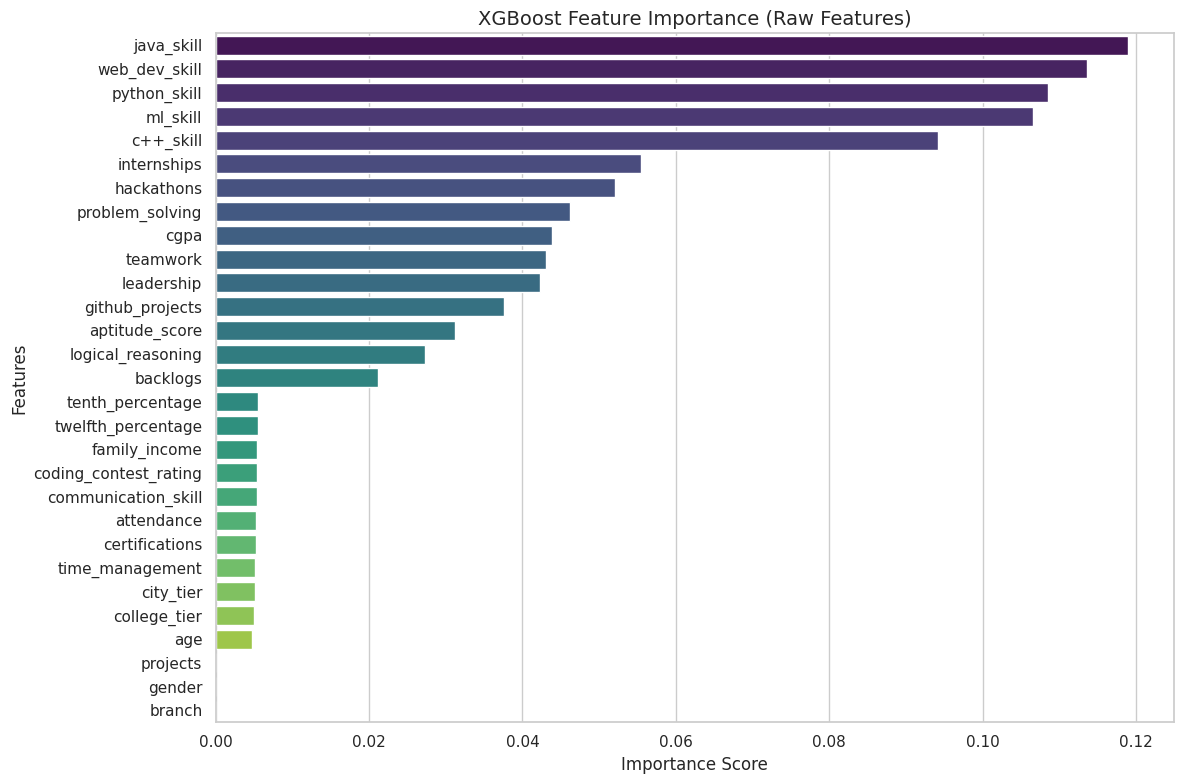

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract and sort feature importances
importances = xgb_raw_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': raw_feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot top feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('XGBoost Feature Importance (Raw Features)', fontsize=14)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()